This file cover ---> token , context window , api cost

Token ---> a token can be a word , some letter , some sysmbol 

In [5]:
import tiktoken

# gpt-6-luna isn't in tiktoken yet, so we use the encoding of recent OpenAI models
encoding = tiktoken.get_encoding("o200k_base")

tokens = encoding.encode("Hi my name is Ed and I like banoffee pie")


print(f"token_id: {tokens}")


for token_id in tokens:
    token_text = encoding.decode([token_id])
    print(f"{token_id} = {token_text}")

token_id: [12194, 922, 1308, 382, 6117, 326, 357, 1299, 9171, 26458, 5148]
12194 = Hi
922 =  my
1308 =  name
382 =  is
6117 =  Ed
326 =  and
357 =  I
1299 =  like
9171 =  ban
26458 = offee
5148 =  pie


### Context Window : ### Context Window

Context Window হলো একটি AI Model-এর নির্দিষ্ট সীমা, যার মাধ্যমে বোঝা যায় একটি conversation-এ AI Model একসঙ্গে সর্বোচ্চ কতটুকু information (Token হিসেবে) ধরে রাখতে ও process করতে পারে।

অর্থাৎ, Context Window নির্ধারণ করে একটি conversation-এ Input Tokens (আমাদের দেওয়া information) এবং Output Tokens (AI-এর generated response) মিলিয়ে সর্বোচ্চ কতগুলো tokens ব্যবহার করা যাবে।

**Example:**

যদি কোনো AI Model-এর Context Window 100,000 Tokens হয়, তাহলে Input ও Output মিলিয়ে সাধারণভাবে সর্বোচ্চ 100,000 Tokens-এর context ব্যবহার করতে পারবে।


## Tk kemne kate 

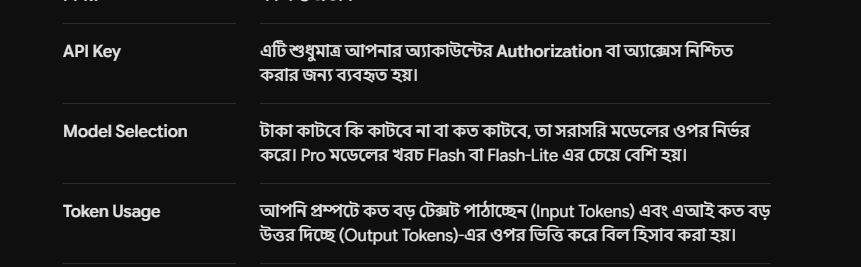

# Difference between using Locally run LLM and using Cloud llm 

### if i use Locally run llm

##### এখানে আসল "খরচ" কোনটা?
- আপনার কোনো কোম্পানির কাছে API বিল বা সাবস্ক্রিপশন ফি দিতে হবে না। তবে লোকালি চালানোর সময় আসল খরচ হয় আপনার ডিভাইসের:

- Hardware / Hardware Resources: 모델 রান করতে আপনার পিসির RAM, GPU (গ্রাফিক্স কার্ড), এবং CPU ব্যবহার হয়।

- বিদ্যুৎ বিল (Electricity): ভারী মডেল (যেমন Pro বা বড় আকারের মডেল) অনেকক্ষণ ধরে চালালে পিসির পাওয়ার ব্যবহার বা বিদ্যুৎ খরচ কিছুটা বাড়তে পারে।

- Storage: 모델গুলো পিসির হার্ডডিস্কে ডাউনলোড করে রাখার জায়গা (Storage) লাগে।

### Pro বা বড় মডেল লোকালি চালালে কী হবে?

##### 1. যেমন কোডে আপনি deepseek-r1:1.5b বা llama3.2 চালাচ্ছেন, এগুলো তুলনামূলক ছোট মডেল এবং যেকোনো সাধারণ ল্যাপটপে সহজে চলে।

- কিন্তু আপনি যদি কোনো বিশাল Pro লেভেলের মডেল লোকালি চালাতে চান:
  টাকা কাটবে না— কারণ মডেল আপনার কম্পিউটারে নামানো আছে।

- পিসি স্লো হতে পারে: যদি আপনার কম্পিউটারে যথেষ্ট পরিমাণ VRAM (GPU RAM) বা System RAM না থাকে, তবে প্রসেসিং       অত্যন্ত ধীরগতির হবে বা পিসি হ্যাং করতে পারে।

### প্যারামিটার (Parameter) দিয়ে কী বোঝায়? (যেমন: 1.5B, 8B, 70B)
##### প্যারামিটার হলো মডেলটির মস্তিষ্কের সাইজ বা নিউরনের সংখ্যা।

- যেমন: deepseek-r1:1.5b মানে হলো এর ১.৫ বিলিয়ন (১৫০ কোটি) প্যারামিটার আছে। অন্যদিকে llama3:8b মানে ৮ বিলিয়ন প্যারামিটার।

- টেইন বা রান করার হিসাব: মডেলটি তৈরি করার সময় (Train) অনেক বড় সুপার কম্পিউটারে কোটি কোটি ডেটা দিয়ে শেখানো হয়—সেটা ডেভেলপাররা করে ফেলে। আপনি যখন লোকালি নামিয়ে চালান, তখন আর নতুন করে ট্রেইন করেন না, শুধু Inference বা রান করেন।

- প্যারামিটার যত বড় হবে (যেমন ৭০বি), মডেলটি তত বেশি বুদ্ধিমান হবে, কিন্তু সেটি রান করতে তত বেশি শক্তিশালী জিপিইউ (GPU) ও বেশি র‍্যাম লাগবে।

### লোকাল মডেলের কি কোনো কনটেক্সট উইন্ডো (Context Window) এর ঝামেলা নেই?
#### <u>কনটেক্সট উইন্ডোর লিমিট লোকাল মডেলেও আছে, তবে সেটির ধরন আলাদা:</u>

- মডেলের নিজস্ব লিমিট: প্রতিটি লোকাল মডেলের একটি জন্মগত বা ডিজাইন করা কনটেক্সট উইন্ডো থাকে (যেমন: কোনোটি ৪,০০০ টোকেন, কোনোটি ৩২,০০০ বা ১ লাখ টোকেন নিতে পারে)। যেমন আপনি যে deepseek-r1:1.5b বা llama3.2 ব্যবহার করছেন, এগুলোর নির্দিষ্ট কনটেক্সট লিমিট আছে। এর বেশি বড় ফাইল বা কোড একসাথে দিলে সেটি প্রসেস করতে পারবে না বা ভুলে যাবে।

- আপনার পিসির র‍্যাম বা VRAM-এর লিমিট (সবচেয়ে বড় ঝামেলা):
    ক্লাউডে সার্ভারের বিশাল মেমরি থাকে তাই তারা বিশাল কনটেক্সট উইন্ডো সামলাতে পারে। কিন্তু লোকাল পিসিতে আপনি যখন অনেক বড় কনটেক্সট (যেমন একসাথে ১০০ পাতার বই বা বিশাল কোডবেস) ইনপুট দেবেন, তখন মডেলটি পুরো টেক্সট পিসির RAM বা GPU VRAM-এ লোড করার চেষ্টা করবে।

- আপনার পিসির র‍্যাম বা VRAM যদি কম হয়, তবে Out of Memory (OOM) এরর আসবে বা পিসি প্রচণ্ড স্লো হয়ে যাবে।

### 1. আসল পেইড মডেলগুলো কেন লোকালি চালানো যায় না?
-   মডেলের ওজন ও কোড গোপনীয় (Closed Source): GPT-4o বা Gemini Pro-এর মতো বড় পেইড মডেলগুলোর সোর্স কোড এবং ইন্টারনাল ওয়েট (Weights) বা ফাইলগুলো ওপেন সোর্স বা সবার জন্য উন্মুক্ত নয়। কোম্পানিগুলো এগুলো নিজেদের সুরক্ষিত সার্ভারে চালায়।

    বিশাল সাইজ: এই মডেলগুলোর সাইজ শত শত জিবি বা টেরাবাইটের হয়ে থাকে, যা সাধারণ বা এমনকি হাই-এন্ড গেমিং পিসিতেও লোড করা অসম্ভব।

### 2. তাহলে মানুষ লোকালি কোন মডেলগুলো চালায়? (Open-Source Models)
- Ollama দিয়ে আপনি যে মডেলগুলো চালান (যেমন: Llama, DeepSeek, Mistral, Qwen, Gemma ইত্যাদি), এগুলোকে বলা হয় Open-Source বা Open-Weights মডেল।

    এই মডেলগুলোর অনেকগুলো আকারে যেমন ছোট (যেমন: ১.৫বি, ৮বি), তেমনি কিছু মডেল বেশ বড় এবং শক্তিশালীও হয় (যেমন: 70B বা তার বেশি)।

    মজার বিষয় হলো, বর্তমানে অনেক ওপেন-সোর্স মডেল (যেমন DeepSeek-R1 বা Llama 3) কোডিং, লজিক এবং রিজনিংয়ের ক্ষেত্রে অনেক পেইড ক্লাউড মডেলের সমকক্ষ বা কাছাকাছি মানের পারফরম্যান্স দেয়।

### 3. একটি বিশেষ কৌশল (API দিয়ে পেইড মডেল ব্যবহার করা)
- আপনি যদি পেইড মডেলগুলোর শক্তি আপনার লোকাল কোডে বা প্রজেক্টে ব্যবহার করতে চান, তবে সেটি Ollama দিয়ে নয়, বরং সরাসরি তাদের API (যেমনটা আপনি গুগলের ক্ষেত্রে করেছিলেন) আপনার কোডে বসিয়ে ব্যবহার করতে হবে। যেমন:

  OpenAI API দিয়ে GPT-4o ব্যবহার করা।

  Google API দিয়ে Gemini Pro ব্যবহার করা।

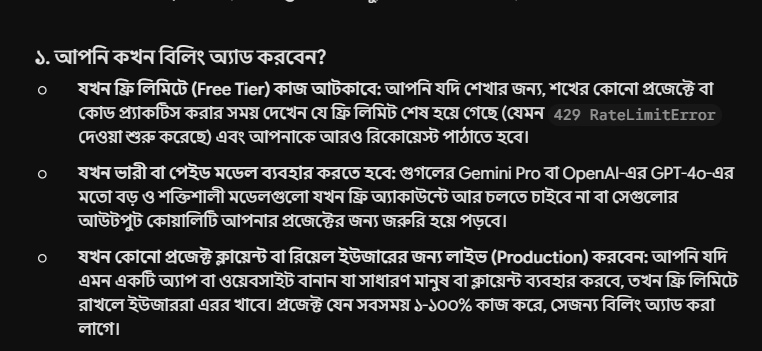